# Fall risk: held-out evaluation

Model 2 scores 10-second windows, trained on development fall groups. The held-out evaluation compares the mean risk of each fall ride with the mean risk of its comparison rides at the same elapsed moments. Groups are never split between training and evaluation. Results below are measured by the `train_fall_risk` DVC stage, not new training runs.

Run `make dev-up` and `uv run dvc repro train_fall_risk` first if the metrics artifact is missing. The training stage requires MLflow. Run this notebook from `notebooks/` or the repository root.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import pandas as pd
from ride_classifier.viz.theme import apply_theme, save_fig

root = Path.cwd()
if not (root / "params.yaml").exists():
    root = root.parent
metrics = json.loads((root / "artifacts/fall_risk_metrics.json").read_text(encoding="utf-8"))
apply_theme()

In [2]:
results = pd.DataFrame([
    {"Gap before fall (s)": 5, "Paired AUC": metrics["held_out_paired_auc"],
     "Window AUC": metrics["held_out_window_auc"], "Fall groups": int(metrics["held_out_n_groups"])},
    {"Gap before fall (s)": 10, "Paired AUC": metrics["held_out_gap10s_paired_auc"],
     "Window AUC": metrics["held_out_gap10s_window_auc"], "Fall groups": int(metrics["held_out_gap10s_n_groups"])},
])
results

,Gap before fall (s),Paired AUC,Window AUC,Fall groups
0,5,0.887805,0.711906,205
1,10,0.756098,0.690968,205


Paired AUC is the fraction of held-out fall groups in which the fall ride's mean risk exceeds the mean risk of its available comparison rides (ties count half). Window AUC is a separate window-level discrimination measure. The 10-second gap is a sanity check on the same held-out groups, not a separately trained model.

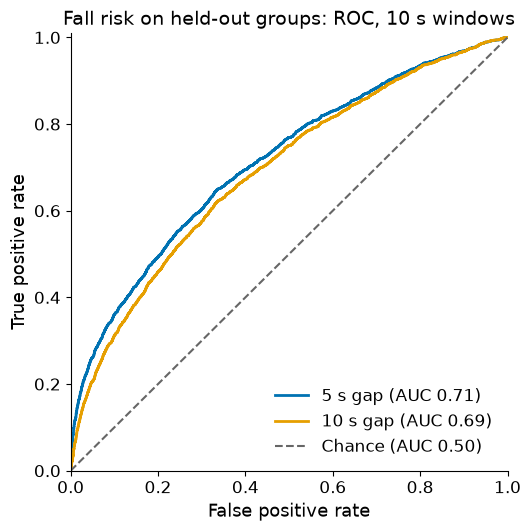

In [3]:
from sklearn.metrics import roc_auc_score, roc_curve

scores = pd.read_csv(root / "artifacts/fall_risk_heldout_scores.csv")
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for (gap, part), color in zip(scores.groupby("gap_s"), ["#0072B2", "#E69F00"], strict=True):
    fpr, tpr, _ = roc_curve(part["label"], part["risk"])
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f"{gap:g} s gap (AUC {roc_auc_score(part['label'], part['risk']):.2f})")
ax.plot([0, 1], [0, 1], "--", color="#666666", label="Chance (AUC 0.50)")
ax.set(xlabel="False positive rate", ylabel="True positive rate", xlim=(0, 1), ylim=(0, 1.01),
       title="Fall risk on held-out groups: ROC, 10 s windows")
ax.legend(loc="lower right", frameon=False)
fig.tight_layout()
save_fig(fig, "F49", "fall_risk_gap_check")
plt.show()

Each curve ranks held-out windows (pre-fall windows of fall rides against windows from their comparison rides) by risk. The window AUC decreases from 0.71 to 0.69 when the gap grows. This window-level metric differs from the paired AUC, the primary evaluation and gate: the paired AUC decreases from 0.89 to 0.76 across the same gap checks. The modest change in window AUC alone does not rule out sensitivity to proximity to the fall.

The drop with the longer gap indicates that part of the measured signal is close to the fall. This is an association on the held-out SRV3490 groups, not evidence of real-world fall probabilities or alert rates: falls were deliberately overrepresented in this dataset. The check uses a shifted 60-second segment, so its change cannot be attributed solely to removing the last five seconds.